In [1]:
# CP322 Assignment 1 — Q2: Decision trees on the SMS Spam Collection dataset

import numpy as np  # pyright: ignore[reportMissingImports]
import pandas as pd # pyright: ignore[reportMissingImports]
import matplotlib.pyplot as plt # pyright: ignore[reportMissingImports]

In [2]:
# ===================== Decision Trees: SMS Spam Collection =====================
# Part (a): load the raw messages, split 70/15/15, THEN vectorize.
# The CountVectorizer is fit only on the training messages so that no
# vocabulary information leaks from the validation/test sets into training.

from sklearn.model_selection import train_test_split  # pyright: ignore[reportMissingImports]
from sklearn.feature_extraction.text import CountVectorizer  # pyright: ignore[reportMissingImports]
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree  # pyright: ignore[reportMissingImports]


def load_data(path="sms.csv", random_state=42):
    """Load the SMS Spam Collection dataset and return vectorized
    train/validation/test splits plus the fitted vectorizer.

    Steps:
      1. Read the raw messages and labels.
      2. Split the RAW messages 70% train / 15% validation / 15% test.
      3. Fit a CountVectorizer on the training messages only, and use
         .transform() (not .fit()) on the validation and test messages.
    """
    df = pd.read_csv(path)
    messages = df["message"].astype(str).to_numpy()
    labels = df["label"].to_numpy()  # 'spam' or 'ham'

    # 70% train, 30% temp -> then split temp in half: 15% val, 15% test
    msg_train, msg_temp, y_train, y_temp = train_test_split(
        messages, labels, train_size=0.70, random_state=random_state)
    msg_val, msg_test, y_val, y_test = train_test_split(
        msg_temp, y_temp, train_size=0.50, random_state=random_state)

    # Fit the vocabulary on the TRAINING messages only
    vectorizer = CountVectorizer()
    X_train = vectorizer.fit_transform(msg_train)
    X_val = vectorizer.transform(msg_val)    # transform only -- no fitting
    X_test = vectorizer.transform(msg_test)  # transform only -- no fitting

    return X_train, y_train, X_val, y_val, X_test, y_test, vectorizer


X_tr, y_tr, X_va, y_va, X_te, y_te, vectorizer = load_data("sms.csv")

print(f"Train:      {X_tr.shape[0]:4d} messages")
print(f"Validation: {X_va.shape[0]:4d} messages")
print(f"Test:       {X_te.shape[0]:4d} messages")
print(f"Vocabulary size (features): {X_tr.shape[1]}")

Train:      3901 messages
Validation:  836 messages
Test:        837 messages
Vocabulary size (features): 7246


In [3]:
# Part (b): select_model -- train decision trees with several max_depth values,
# evaluate each on the validation set (manual loop, no GridSearchCV).

def select_model(X_train, y_train, X_val, y_val,
                 depths=(2, 5, 10, 20, 50, 100), random_state=42):
    """Train a DecisionTreeClassifier for each max_depth in `depths`,
    print its validation accuracy, and return the best model and the
    dict of {max_depth: validation accuracy}."""
    results = {}
    best_model, best_depth, best_acc = None, None, -1.0

    for depth in depths:
        clf = DecisionTreeClassifier(max_depth=depth, random_state=random_state)
        clf.fit(X_train, y_train)
        val_acc = np.mean(clf.predict(X_val) == y_val)
        results[depth] = val_acc
        print(f"max_depth = {depth:3d}   validation accuracy = {val_acc:.4f}")
        if val_acc > best_acc:
            best_model, best_depth, best_acc = clf, depth, val_acc

    print(f"\nBest: max_depth = {best_depth} "
          f"(validation accuracy = {best_acc:.4f})")
    return best_model, best_depth, results


best_tree, best_depth, val_results = select_model(X_tr, y_tr, X_va, y_va)

max_depth =   2   validation accuracy = 0.9222
max_depth =   5   validation accuracy = 0.9390
max_depth =  10   validation accuracy = 0.9641
max_depth =  20   validation accuracy = 0.9677
max_depth =  50   validation accuracy = 0.9629
max_depth = 100   validation accuracy = 0.9629

Best: max_depth = 20 (validation accuracy = 0.9677)


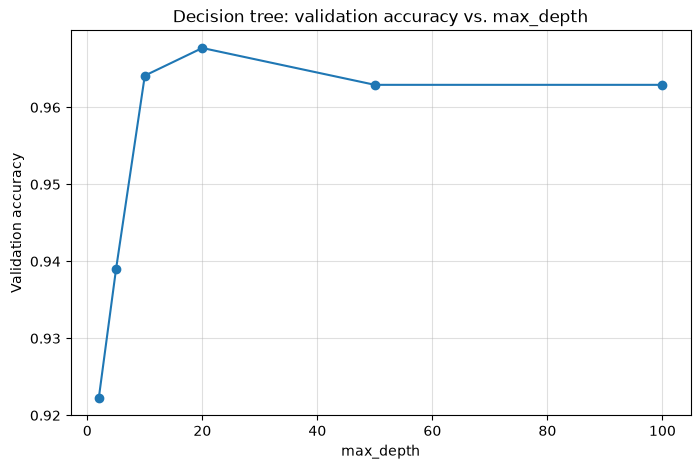

Test accuracy with max_depth = 20: 0.9689 (811/837 correct)


In [4]:
# Plot validation accuracy vs. max_depth, then report the test accuracy
# of the best model (the only time the test set is used).

depths = list(val_results.keys())
accs = [val_results[d] for d in depths]

plt.figure(figsize=(8, 5))
plt.plot(depths, accs, marker="o")
plt.xlabel("max_depth")
plt.ylabel("Validation accuracy")
plt.title("Decision tree: validation accuracy vs. max_depth")
plt.grid(True, alpha=0.4)
plt.show()

test_acc = np.mean(best_tree.predict(X_te) == y_te)
print(f"Test accuracy with max_depth = {best_depth}: {test_acc:.4f} "
      f"({int(round(test_acc * len(y_te)))}/{len(y_te)} correct)")

|--- call <= 0.50
|   |--- txt <= 0.50
|   |   |--- www <= 0.50
|   |   |   |--- truncated branch of depth 18
|   |   |--- www >  0.50
|   |   |   |--- truncated branch of depth 2
|   |--- txt >  0.50
|   |   |--- to <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- to >  0.50
|   |   |   |--- truncated branch of depth 2
|--- call >  0.50
|   |--- me <= 0.50
|   |   |--- ll <= 0.50
|   |   |   |--- truncated branch of depth 18
|   |   |--- ll >  0.50
|   |   |   |--- class: ham
|   |--- me >  0.50
|   |   |--- u4 <= 0.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- u4 >  0.50
|   |   |   |--- class: spam



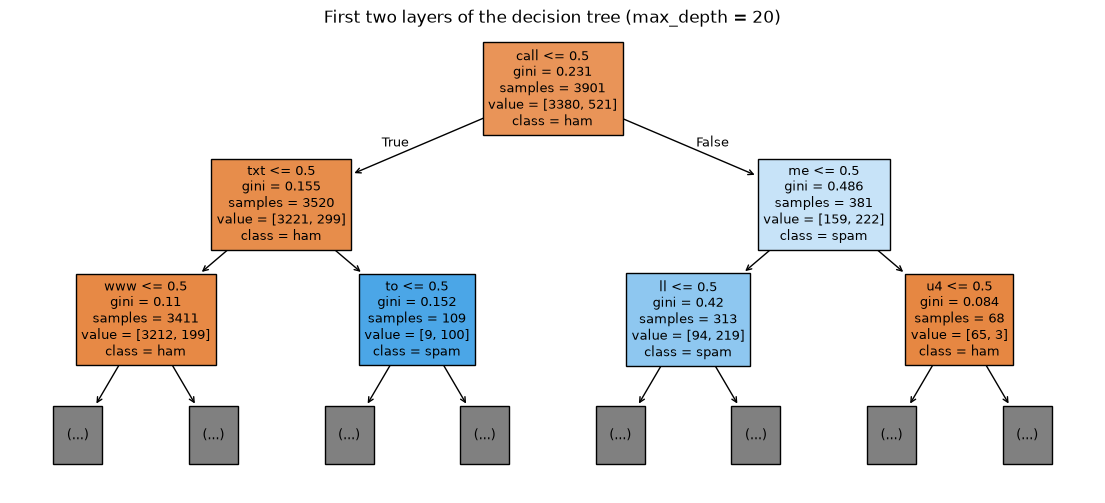

In [5]:
# Part (c): visualize the first two layers of the best tree.

feature_names = vectorizer.get_feature_names_out()

# Plain-text view of the top of the tree
print(export_text(best_tree, feature_names=list(feature_names), max_depth=2))

# Diagram of the same two layers
plt.figure(figsize=(14, 6))
plot_tree(best_tree, max_depth=2, feature_names=feature_names,
          class_names=best_tree.classes_, filled=True, fontsize=9)
plt.title(f"First two layers of the decision tree (max_depth = {best_depth})")
plt.show()

**Comment on the top split (part c):** The root of the tree splits on whether the word "call" appears in the message. This makes intuitive sense for spam detection: spam SMS messages very often push the recipient to take an action like "call this number to claim your prize," so the presence of "call" is a strong spam signal. The second-layer splits reinforce this — on the no-"call" side the tree checks for "txt" and then "www" (other classic spam call-to-action words, e.g. "txt WIN to 80086" or a web link), while on the "call" side it checks for "me", since "call me" is a very common *ham* phrase between people who know each other. So the top of the tree is essentially separating promotional call-to-action language from ordinary personal conversation.